In [15]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import datetime
import warnings
import sidrapy
from bcb import sgs, Expectativas

# === Settings and Dates ===

warnings.filterwarnings('ignore')
np.random.seed(42)
initial_date = '2002-01-01'
DATA_FINAL = datetime.datetime.now().strftime('2026-06-30')

# === Data Extraction ===

print("Initiating data extraction...")

codes_sgs = {
    'IPCA_Mensal': 433,
    'Selic_Meta': 432,
    'IBC_Br': 24363,
    'Dolar_PTAX': 1
}

def all_sgs(code, start_date):
    start = pd.to_datetime(start_date)
    end = pd.Timestamp.today()
    
    chunks = []
    current_start = start

    while current_start < end:
    # Jumping t years to ignore the time limit

        current_end = min(current_start + pd.DateOffset(years=5), end)
        
        d_start_str = current_start.strftime('%Y-%m-%d')
        d_end_str = current_end.strftime('%Y-%m-%d')
        print(f"   -> Downloading data: {d_start_str} until {d_end_str}...")
        
        # Downloading data group
        chunk = sgs.get(code, start=d_start_str, end=d_end_str)
        chunks.append(chunk)
        
        # Updating the data for the new data group
        current_start = current_end + pd.Timedelta(days=1)
        
        # Concat all data in only one DataFrame
        df_final = pd.concat(chunks)

        # Removing duplicates
        df_final = df_final[~df_final.index.duplicated(keep='first')]
    
    return df_final

# Execute the functions: 
df_sgs = all_sgs(codes_sgs, initial_date)
df_sgs = df_sgs.dropna()
display(df_sgs)

Initiating data extraction...
   -> Downloading data: 2002-01-01 until 2007-01-01...
   -> Downloading data: 2007-01-02 until 2012-01-02...
   -> Downloading data: 2012-01-03 until 2017-01-03...
   -> Downloading data: 2017-01-04 until 2022-01-04...
   -> Downloading data: 2022-01-05 until 2026-07-05...


,IPCA_Mensal,Selic_Meta,IBC_Br,Dolar_PTAX
Date,,,,
2003-04-01,0.97,26.50,71.43536,3.3359
2003-07-01,0.20,26.00,72.04189,2.8443
2003-08-01,0.34,24.50,70.93748,3.0006
2003-09-01,0.78,22.00,71.91584,2.9840
2003-10-01,0.29,20.00,73.44254,2.9034
...,...,...,...,...
2025-08-01,-0.11,15.00,110.47825,5.5436
2025-09-01,0.48,15.00,109.57602,5.4378
2025-10-01,0.09,15.00,110.16742,5.3208


In [ ]:
from fredapi import Fred

API_KEY = 'Insert your API Key here!'
fred = Fred(api_key = API_KEY)
start_date = initial_date # 2002-01-01

# FED FUNDS: Federal Funds effective Rate (Monthly)
fed_funds = fred.get_series('FEDFUNDS', observation_start=start_date)

#CPIAUCSL: Consumer Price Index for All Urban Consumers (Monthly)
us_cpi = fred.get_series('CPIAUCSL', observation_start=start_date)

# Construction and Formatting DataFrame
df_fed = pd.DataFrame({
    'Fed_Funds': fed_funds,
    'US_CPI': us_cpi
})

df_fed.index = df_fed.index + pd.offsets.MonthBegin(0)
df_fed.index.name = 'Date'

# Drop any potential missing values from the raw series
df_fed = df_fed.dropna()
print("FRED data successfully structured!")
display(df_fed)

# Final dataset:
df_final = pd.concat([df_sgs, df_fed], axis=1).dropna()
df_final

FRED data successfully structured!


,Fed_Funds,US_CPI
Date,,
2002-01-01,1.73,177.700
2002-02-01,1.74,178.000
2002-03-01,1.73,178.500
2002-04-01,1.75,179.300
2002-05-01,1.75,179.500
...,...,...
2026-01-01,3.64,326.588
2026-02-01,3.64,327.460
2026-03-01,3.64,330.293


,IPCA_Mensal,Selic_Meta,IBC_Br,Dolar_PTAX,Fed_Funds,US_CPI
Date,,,,,,
2003-04-01,0.97,26.50,71.43536,3.3359,1.26,183.200
2003-07-01,0.20,26.00,72.04189,2.8443,1.01,183.700
2003-08-01,0.34,24.50,70.93748,3.0006,1.03,184.500
2003-09-01,0.78,22.00,71.91584,2.9840,1.01,185.100
2003-10-01,0.29,20.00,73.44254,2.9034,1.01,184.900
...,...,...,...,...,...,...
2025-07-01,0.26,15.00,113.21721,5.4511,4.33,322.169
2025-08-01,-0.11,15.00,110.47825,5.5436,4.33,323.291
2025-09-01,0.48,15.00,109.57602,5.4378,4.22,324.245


Statistics for IPCA_Mensal: Mean: 0.4420, Median: 0.4400, Std: 0.3240, Skewness: -0.1144, Kurtosis: 0.8181


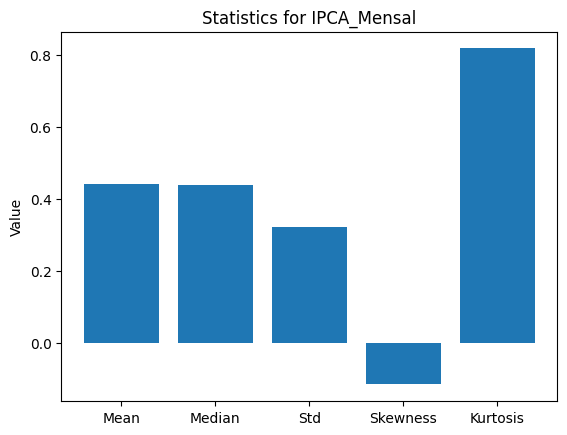

Statistics for Selic_Meta: Mean: 11.6494, Median: 11.3750, Std: 4.6049, Skewness: 0.2782, Kurtosis: 0.7069


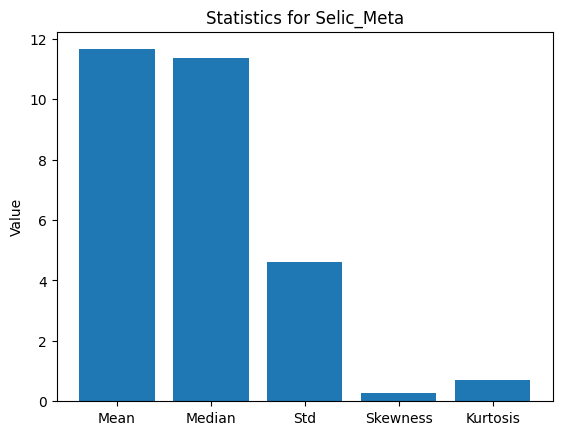

Statistics for IBC_Br: Mean: 94.3514, Median: 96.4971, Std: 10.1924, Skewness: -0.6251, Kurtosis: -0.2536


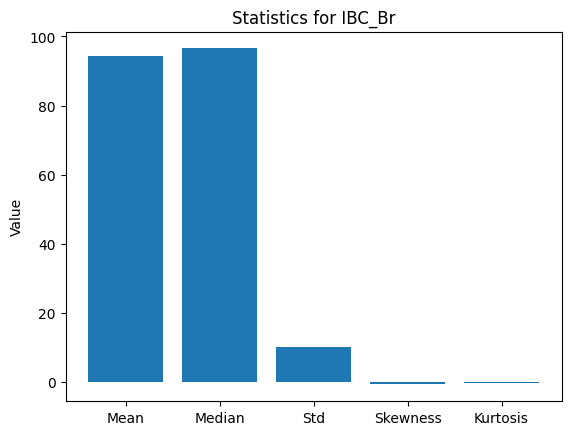

Statistics for Dolar_PTAX: Mean: 3.2677, Median: 2.9923, Std: 1.3708, Skewness: 0.4882, Kurtosis: -1.2107


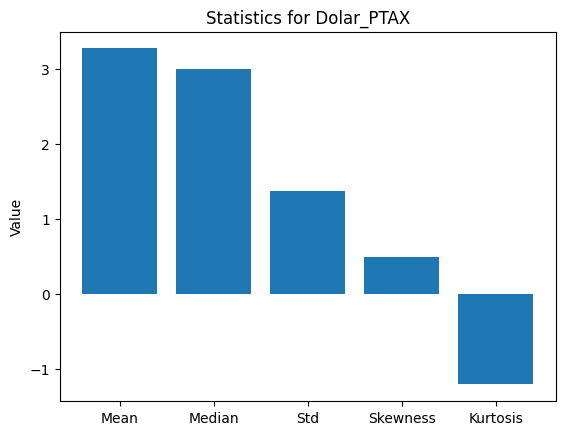

Statistics for Fed_Funds: Mean: 1.7195, Median: 1.0050, Std: 1.8794, Skewness: 0.8386, Kurtosis: -0.8186


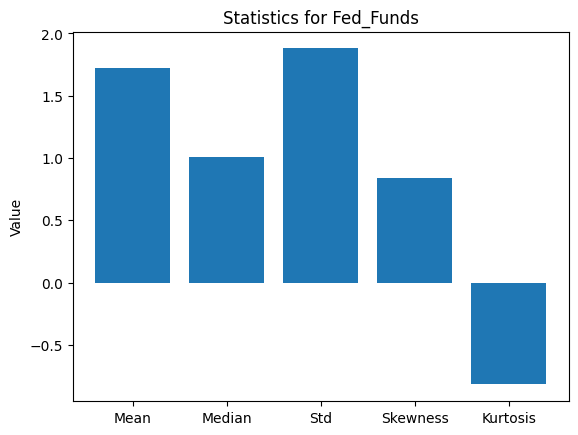

Statistics for US_CPI: Mean: 240.8725, Median: 236.3600, Std: 38.1798, Skewness: 0.6394, Kurtosis: -0.3981


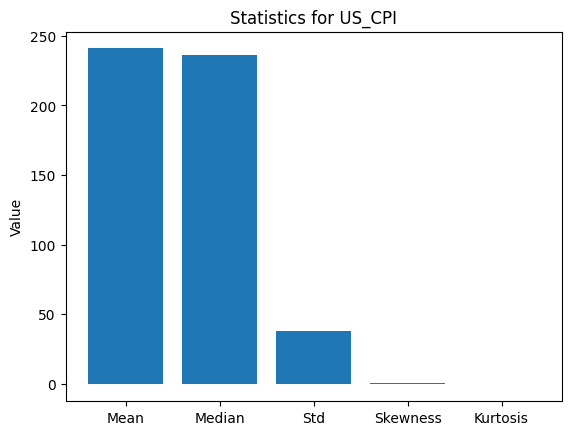

In [17]:
# === Statistical Analysis ===

for i in df_final.columns:
    stats = df_final[i].mean(), df_final[i].median(), df_final[i].std(), df_final[i].skew(), df_final[i].kurtosis()
    stat_names = ['Mean', 'Median', 'Std', 'Skewness', 'Kurtosis']
    
    print(f'Statistics for {i}: Mean: {stats[0]:.4f}, Median: {stats[1]:.4f}, Std: {stats[2]:.4f}, Skewness: {stats[3]:.4f}, Kurtosis: {stats[4]:.4f}')
    
    # Bar graph
    plt.figure()
    plt.bar(stat_names, stats)
    plt.title(f'Statistics for {i}')
    plt.ylabel('Value')
    plt.show()


In [18]:
# === Pre-processing Data ===

df_final['Selic_Ret'] = df_final['Selic_Meta'].pct_change() * 100 # Simple Returns
df_final['Fed_Ret'] = df_final['Fed_Funds'].pct_change() * 100 # Simple Returns
df_final['Selic_Diff'] = df_final['Selic_Meta'].diff() # Differentiation 

df_model = df_final.dropna()
print(df_model[['Selic_Meta', 'Selic_Ret', 'Selic_Diff']])

            Selic_Meta  Selic_Ret  Selic_Diff
Date                                         
2003-07-01       26.00  -1.886792       -0.50
2003-08-01       24.50  -5.769231       -1.50
2003-09-01       22.00 -10.204082       -2.50
2003-10-01       20.00  -9.090909       -2.00
2003-12-01       17.50 -12.500000       -2.50
...                ...        ...         ...
2025-07-01       15.00   5.263158        0.75
2025-08-01       15.00   0.000000        0.00
2025-09-01       15.00   0.000000        0.00
2025-12-01       15.00   0.000000        0.00
2026-04-01       14.75  -1.666667       -0.25

[163 rows x 3 columns]


Initiating Stationarity Test
Original: p-valor = 0.0991 the series is Non-Stationary
Diferença: p-valor = 0.0000 the series is Stationary


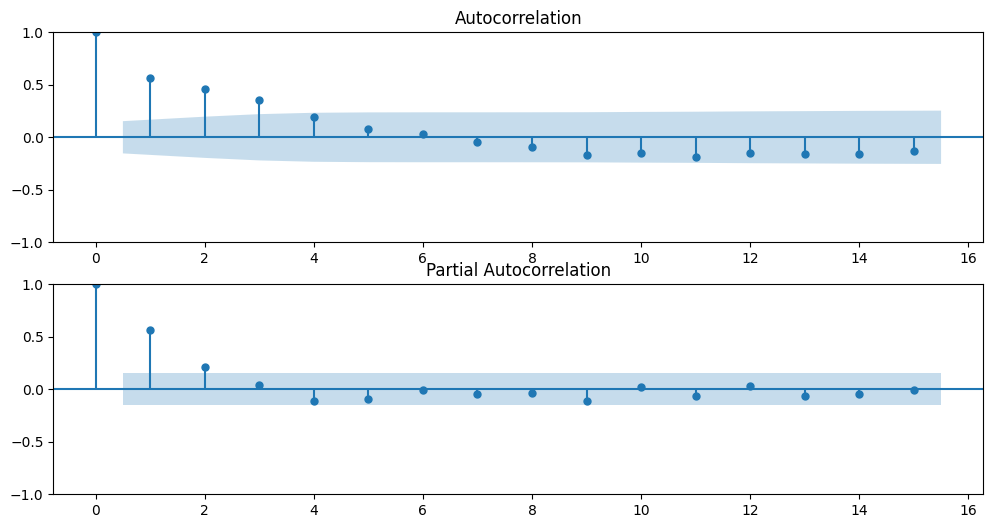

In [19]:
# === Stationarity and Autocorrelation Analysis ===
from statsmodels.tsa.stattools import adfuller 
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("Initiating Stationarity Test")
for name, serie in [('Original', df_model['Selic_Meta']), ('Diferença', df_model['Selic_Diff'])]:
    result = adfuller(serie.dropna())
    print(f'{name}: p-valor = {result[1]:.4f} the series is {'Stationary' if result[1] < 0.05 else 'Non-Stationary'}')

# Plot ACF/PACF test for serie diff (this will define the ARIMA model parameters)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(df_model['Selic_Diff'].dropna(), lags=15, ax=ax1)
plot_pacf(df_model['Selic_Diff'].dropna(), lags=15, ax=ax2)
plt.show()

In [20]:
# === ARIMA Model (Forecast for 12 months) ===
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA model
model = ARIMA(df_model['Selic_Meta'], order=(1, 1, 1)) # ARIMA (p,d,q)
model_fit = model.fit()
print(model_fit.summary())

# Forecast the next 12 months:
print('Initiating Forecast for the Interest Rate for the next 12 months...')
forecast_arima = model_fit.forecast(steps=12)

                               SARIMAX Results                                
Dep. Variable:             Selic_Meta   No. Observations:                  163
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -154.847
Date:                Sun, 05 Jul 2026   AIC                            315.694
Time:                        13:10:38   BIC                            324.957
Sample:                             0   HQIC                           319.455
                                - 163                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8020      0.068     11.747      0.000       0.668       0.936
ma.L1         -0.3392      0.116     -2.923      0.003      -0.567      -0.112
sigma2         0.3948      0.021     19.107      0.0

In [21]:
# === Applying E-GARCH Model for Volatility Forecasting ===

from arch import arch_model

# For E-GARCH model, we will use the logarithmic returns of the Selic Rate, as it is a common practice in financial time series analysis to model volatility. 
# An important information is that the E-GARCH model works better with log returns, so this is why we will use them, instead of the simple returns, previously calculated. 

df_final['Selic_Log_Ret'] = np.log(df_final['Selic_Meta'] / df_final['Selic_Meta'].shift(1)) * 100 # Log Returns
returns = df_final['Selic_Log_Ret'].dropna()

# Adjust EGARCH (1,1) with normal distribution

garch_model = arch_model(returns, vol='Garch', p=1, q=1, dist='normal')
garch_res = garch_model.fit(update_freq=5, disp='off')
print(garch_res.summary())

print('Initiating Variance forecast for the next 12 months...')
garch_forecast = garch_res.forecast(horizon=12)
vol_forecast = np.sqrt(garch_forecast.variance.iloc[-1].values)

print('n📊 Forecast Vol (standard deviation of Logarithmic Returns) for the next 12 months:')
for i, vol in enumerate(vol_forecast, 1):
    print(f'Month {i}: {vol:.4f}%')

                     Constant Mean - GARCH Model Results                      
Dep. Variable:          Selic_Log_Ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -560.885
Distribution:                  Normal   AIC:                           1129.77
Method:            Maximum Likelihood   BIC:                           1142.14
                                        No. Observations:                  163
Date:                Sun, Jul 05 2026   Df Residuals:                      162
Time:                        13:10:39   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.3105      0.746     -0.416      0.677 [ -1.773,  1.15

In [48]:
# === Download Focus Market Expectations (BCB) ===
from bcb import sgs
import warnings
warnings.filterwarnings('ignore')

# Focus series codes (median expectations)
# Source: https://www3.bcb.gov.br/sgspub/localizarseries/localizarSeries.do?method=prepararTelaLocalizarSeries
focus_series = {
    'IPCA_12M': 4473,      # IPCA 12 months ahead (median)
    'SELIC_12M': 4475,     # Selic rate 12 months ahead (median)
    'PIB_12M': 4476,       # GDP growth 12 months ahead (median)
    'DOLAR_12M': 4477,     # Exchange rate (R$/US$) 12 months ahead (median)
}

downloaded = {}
for name, code in focus_series.items():
    try:
        # Try to download from a recent date to ensure data exists
        series = sgs.get(code, start='2020-01-01')
        if series is not None and not series.empty:
            downloaded[name] = series
            print(f"✓ Downloaded {name} (code {code}) - {len(series)} observations")
        else:
            # Try with an even more recent start date
            series = sgs.get(code, start='2022-01-01')
            if series is not None and not series.empty:
                downloaded[name] = series
                print(f"✓ Downloaded {name} (code {code}) - {len(series)} observations (using recent start)")
            else:
                print(f"⚠️ Warning: Could not download {name} (code {code})")
    except Exception as e:
        print(f"❌ Error downloading {name}: {e}")

if not downloaded:
    raise ValueError("No Focus series could be downloaded. Check your internet connection or the SGS codes.")

# Create DataFrame by concatenating series along columns (aligns by index automatically)
df_focus = pd.concat(downloaded, axis=1)
df_focus.columns = downloaded.keys()  # Rename columns to series names
df_focus.index.name = 'Date'

print(f"\nFocus data downloaded: {df_focus.shape[0]} rows, {df_focus.shape[1]} columns")
print("Sample:")
print(df_focus.head())

# Resample to monthly frequency (take last available value in each month)
df_focus_monthly = df_focus.resample('M').last()

# Ensure the index is month-end (to match df_final's index)
df_focus_monthly.index = df_focus_monthly.index + pd.offsets.MonthEnd(0)

# Ensure df_final has a DatetimeIndex
if not isinstance(df_final.index, pd.DatetimeIndex):
    df_final.index = pd.to_datetime(df_final.index)

# Merge focus data into df_final (left join to keep all original rows)
df_final = df_final.join(df_focus_monthly, how='left')

# Forward fill missing values (for months where Focus data was not available)
df_final[downloaded.keys()] = df_final[downloaded.keys()].fillna(method='ffill')

# Check if any columns are still NaN (if so, backward fill)
df_final[downloaded.keys()] = df_final[downloaded.keys()].fillna(method='bfill')

print("\n✅ Focus data successfully integrated into df_final!")
print("Latest focus expectations:")
print(df_final[['Selic_Meta'] + list(downloaded.keys())].tail())

✓ Downloaded IPCA_12M (code 4473) - 77 observations
✓ Downloaded SELIC_12M (code 4475) - 77 observations
✓ Downloaded PIB_12M (code 4476) - 77 observations
✓ Downloaded DOLAR_12M (code 4477) - 77 observations

Focus data downloaded: 77 rows, 4 columns
Sample:
            IPCA_12M  SELIC_12M   PIB_12M  DOLAR_12M
Date                                                
2020-01-01  78470.51  -13320.53  68798.43    1914.40
2020-02-01  78608.29  -13246.57  69341.46    1929.16
2020-03-01  82635.18  -13087.35  72225.39    1904.77
2020-04-01  84462.38  -13175.38  73884.45    1904.79
2020-05-01  85460.29  -13388.33  73955.68    1952.54


ValueError: columns overlap but no suffix specified: Index(['IPCA_12M', 'SELIC_12M', 'PIB_12M', 'DOLAR_12M'], dtype='object')

In [50]:
# === Feature Engineering for XGBoost Machine Learning Model ===

for lag in range(1, 13):
    df_final[f'Lag_{lag}'] = df_final['Selic_Meta'].shift(lag)

# Moving Average for Selic Meta:
df_final['MA_3'] = df_final['Selic_Meta'].rolling(3).mean()
df_final['MA_6'] = df_final['Selic_Meta'].rolling(6).mean()
df_final['MA_12'] = df_final['Selic_Meta'].rolling(12).mean()

# Adding exogenous variables 
for lag in [1, 3, 6, 12]:
    df_final[f'IPCA_Lag_{lag}'] = df_final['IPCA_Mensal'].shift(lag)
    df_final[f'Dolar_Lag_{lag}'] = df_final['Dolar_PTAX'].shift(lag)
    df_final[f'Fed_Lag_{lag}'] = df_final['Fed_Funds'].shift(lag)
    #df_final[f'Focus_Selic_Lag_{lag}'] = df_final['Focus_Selic_12m'].shift(lag)
    #df_final[f'Focus_IPCA_Lag_{lag}'] = df_final['Focus_IPCA_12m'].shift(lag)

# Removing NAs from the Dataframe
df_final = df_final.dropna()

# Defining X and y:
target = 'Selic_Meta'
feature_cols = [col for col in df_final.columns if col not in ['Date', target, 'Selic_Ret', 'Selic_Diff', 'Selic_Log_Ret']]
X = df_final[feature_cols]
y = df_final[target]

# Split all data in 80/20 or 70/30. In this case, we'll use 80/20.

split_idx = int(0.8*len(X))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

In [51]:
# === Machine Learning Model (XGBoost) for forecasting the Selic Rate ===
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor 
import optuna

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    model = XGBRegressor(**params, random_state=42, verbosity=0)
    tscv = TimeSeriesSplit(n_splits=5)
    scores = []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        scores.append(rmse)
    return np.mean(scores)

# Optuna's Optimization for Hyperparameters
print('Running Optuna,s hyperparameters optimizer...')
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50, show_progress_bar=True)  

best_params = study.best_params
print("Best parameters:", best_params)

# Training XGBoost Model

xgb_model = XGBRegressor(**best_params, random_state=42, verbosity=0)
xgb_model.fit(X_train, y_train)

# Predictions and Evaluations
y_pred_xgb = xgb_model.predict(X_test)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
print(f"XGBoost - RMSE: {rmse_xgb:.4f}, MAE: {mae_xgb:.4f}")

[I 2026-07-05 20:46:48,933] A new study created in memory with name: no-name-9a88a8a5-5093-4936-81d1-dbcd05d172e1


Running Optuna,s hyperparameters optimizer...


  0%|          | 0/50 [00:00<?, ?it/s]

[W 2026-07-05 20:46:48,964] Trial 0 failed with parameters: {'n_estimators': 951, 'max_depth': 9, 'learning_rate': 0.12386502029178365, 'subsample': 0.9768899040823249, 'colsample_bytree': 0.6975706511080303, 'reg_alpha': 0.06483000400252753, 'reg_lambda': 4.8073834527896215} because of the following error: ValueError('Cannot have number of folds=6 greater than the number of samples=0.').
Traceback (most recent call last):
  File "c:\Users\henri\AppData\Local\Programs\Python\Python313\Lib\site-packages\optuna\study\_optimize.py", line 201, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\henri\AppData\Local\Temp\ipykernel_3436\1681547986.py", line 21, in objective
    for train_idx, val_idx in tscv.split(X_train):
                              ~~~~~~~~~~^^^^^^^^^
  File "c:\Users\henri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py", line 1289, in _split
    raise ValueError(
    ...<2 lines>...
    )
ValueError: Cannot have 

ValueError: Cannot have number of folds=6 greater than the number of samples=0.

In [30]:
# === Ridge Regression with Optuna ===
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import numpy as np
import optuna

scaler_ridge = StandardScaler()
X_train_scaled = scaler_ridge.fit_transform(X_train)
X_test_scaled = scaler_ridge.transform(X_test)

def objective_ridge(trial):
    alpha = trial.suggest_float('alpha', 1e-3, 100.0, log=True)
    model = Ridge(alpha=alpha)
    tscv = TimeSeriesSplit(n_splits=5)
    scores = []
    for train_idx, val_idx in tscv.split(X_train_scaled):
        X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        scores.append(rmse)
    return np.mean(scores)

study_ridge = optuna.create_study(direction='minimize')
study_ridge.optimize(objective_ridge, n_trials=30, show_progress_bar=True)

best_ridge = Ridge(alpha=study_ridge.best_params['alpha'])
best_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = best_ridge.predict(X_test_scaled)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
print(f"RMSE da Ridge no teste: {rmse_ridge:.4f}")

[I 2026-07-05 14:30:20,446] A new study created in memory with name: no-name-00b8a770-065e-4443-84cf-f1bcd3cc20df


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-07-05 14:30:20,459] Trial 0 finished with value: 2.0802466600659746 and parameters: {'alpha': 0.05333374973465431}. Best is trial 0 with value: 2.0802466600659746.
[I 2026-07-05 14:30:20,467] Trial 1 finished with value: 2.141831256809808 and parameters: {'alpha': 0.006922339289924328}. Best is trial 0 with value: 2.0802466600659746.
[I 2026-07-05 14:30:20,482] Trial 2 finished with value: 2.1813775763777628 and parameters: {'alpha': 7.691753941187685}. Best is trial 0 with value: 2.0802466600659746.
[I 2026-07-05 14:30:20,495] Trial 3 finished with value: 2.3422805065632524 and parameters: {'alpha': 28.993032751925025}. Best is trial 0 with value: 2.0802466600659746.
[I 2026-07-05 14:30:20,505] Trial 4 finished with value: 2.4766393747858233 and parameters: {'alpha': 54.780006602905175}. Best is trial 0 with value: 2.0802466600659746.
[I 2026-07-05 14:30:20,516] Trial 5 finished with value: 2.206451632431274 and parameters: {'alpha': 0.8981279586658116}. Best is trial 0 with v

In [26]:
# === Interactive Forecast for the next 12 months (XGBoost) ===

last_row = X.iloc[-1:].copy()
forecast_steps = 12
forecast_xgb = []

for _ in range(forecast_steps):
    pred = xgb_model.predict(last_row)[0]
    forecast_xgb.append(pred)
    
    new_row = last_row.iloc[-1:].copy()
    for lag in range(12, 0, -1):
        if lag == 1:
            new_row[f'Lag_{lag}'] = pred
        else:
            new_row[f'Lag_{lag}'] = last_row.iloc[-1][f'Lag_{lag-1}']
    new_row['MA_3'] = (new_row['Lag_1'] + new_row['Lag_2'] + new_row['Lag_3']) / 3
    new_row['MA_6'] = (new_row['Lag_1'] + new_row['Lag_2'] + new_row['Lag_3'] + new_row['Lag_4'] + new_row['Lag_5'] + new_row['Lag_6']) / 6
    new_row['MA_12'] = sum([new_row[f'Lag_{i}'] for i in range(1, 13)]) / 12
    # Mantém as variáveis exógenas iguais (último valor conhecido) – você pode melhorar depois
    last_row = new_row

# Arredondar para múltiplo de 0.25 (baseado na diferença em relação ao último real)
last_actual = df_model['Selic_Meta'].iloc[-1]
forecast_xgb = np.array(forecast_xgb)
forecast_diff = np.diff(np.concatenate([[last_actual], forecast_xgb]))
forecast_diff_rounded = np.round(forecast_diff / 0.25) * 0.25
forecast_xgb_rounded = np.cumsum(np.concatenate([[last_actual], forecast_diff_rounded]))[1:]

print("\nPrevisão XGBoost (12 meses, arredondada para 0.25 p.p.):")
for i, val in enumerate(forecast_xgb_rounded, 1):
    print(f"Mês {i}: {val:.2f}%")


Previsão XGBoost (12 meses, arredondada para 0.25 p.p.):
Mês 1: 13.75%
Mês 2: 13.50%
Mês 3: 13.50%
Mês 4: 13.25%
Mês 5: 13.00%
Mês 6: 13.00%
Mês 7: 12.25%
Mês 8: 11.75%
Mês 9: 11.75%
Mês 10: 11.75%
Mês 11: 11.50%
Mês 12: 11.50%


In [37]:
# === Adapt Forecast to Copom Meeting Dates (every ~45 days) ===
from datetime import datetime, timedelta

# Current date (July 5, 2026)
current_date = datetime(2026, 7, 5)

# The next Copom meeting is scheduled for early August 2026 (e.g., Aug 4-5).
# We'll set the first meeting date to August 5, 2026.
first_meeting = datetime(2026, 8, 5)

# Generate next 8 Copom meeting dates (roughly every 45 days)
meeting_dates = []
next_date = first_meeting
for _ in range(8):
    meeting_dates.append(next_date)
    next_date = next_date + timedelta(days=45)   # update for the next meeting

# Determine the month corresponding to the first forecast (last data month + 1)
# Last data month in df_model (should be April 2026)
last_month = df_model.index[-1]   # this is a DatetimeIndex
first_forecast_month = last_month + pd.offsets.MonthBegin(1)  # May 2026
monthly_dates = pd.date_range(start=first_forecast_month, periods=12, freq='MS')

# For each meeting date, pick the forecast from the closest month
forecast_at_meetings = []
for meeting in meeting_dates:
    # Compute absolute day differences to each monthly forecast date
    diff_days = [abs((meeting - m).days) for m in monthly_dates]
    idx_min = np.argmin(diff_days)
    forecast_at_meetings.append(forecast_xgb_rounded[idx_min])

# Display results
print("--- Selic Forecast for Next Copom Meetings ---")
for i, (date, rate) in enumerate(zip(meeting_dates, forecast_at_meetings), 1):
    print(f"Meeting {i}: {date.strftime('%d/%m/%Y')} -> Forecasted Selic: {rate:.2f}%")

--- Selic Forecast for Next Copom Meetings ---
Meeting 1: 05/08/2026 -> Forecasted Selic: 13.25%
Meeting 2: 19/09/2026 -> Forecasted Selic: 13.00%
Meeting 3: 03/11/2026 -> Forecasted Selic: 12.25%
Meeting 4: 18/12/2026 -> Forecasted Selic: 11.75%
Meeting 5: 01/02/2027 -> Forecasted Selic: 11.75%
Meeting 6: 18/03/2027 -> Forecasted Selic: 11.50%
Meeting 7: 02/05/2027 -> Forecasted Selic: 11.50%
Meeting 8: 16/06/2027 -> Forecasted Selic: 11.50%


In [35]:
# === Scenarios and Signals ===
# Use the rounded XGBoost forecast as baseline
baseline = forecast_xgb_rounded

# Manually set the current Selic rate to 14.25% (as informed by the user)
actual_selic = 14.25

# Forecasted volatility from GARCH (average over the 12-month horizon)
sigma = np.mean(vol_forecast)

# Compute high and low scenarios (base ± 1.5 * sigma)
high_scenario = baseline + (1.5 * sigma)
low_scenario = baseline - (1.5 * sigma)

# Round scenarios to the nearest 0.25 p.p. (to respect BCB's step size)
high_scenario = np.round(high_scenario / 0.25) * 0.25
low_scenario = np.round(low_scenario / 0.25) * 0.25

# Create DataFrame for display
df_scenarios = pd.DataFrame({
    'Month': list(range(1, 13)),
    'Base': baseline,
    'High (+1.5σ)': high_scenario,
    'Low (-1.5σ)': low_scenario
})
print("--- Selic Scenarios (Next 12 months) ---")
print(df_scenarios)

# Rebalancing signal logic
pred_mean = np.mean(baseline)
if pred_mean > (actual_selic + 0.5):
    signal = "🔴 Reduce Stocks (Rising Interest Rates)"
elif pred_mean < (actual_selic - 0.5):
    signal = "🟢 Increase Stocks (Falling Interest Rates)"
else:
    signal = "🟡 Maintain Position (Stable Rates)"

print("\n" + "="*50)
print(f"Current Selic: {actual_selic:.2f}%")
print(f"Forecasted Average (12 months): {pred_mean:.2f}%")
print(f"Signal: {signal}")
print("="*50)

--- Selic Scenarios (Next 12 months) ---
    Month   Base  High (+1.5σ)  Low (-1.5σ)
0       1  13.75         25.50         2.00
1       2  13.50         25.25         1.75
2       3  13.50         25.25         1.75
3       4  13.25         25.00         1.50
4       5  13.00         24.75         1.25
5       6  13.00         24.75         1.25
6       7  12.25         24.00         0.50
7       8  11.75         23.50         0.00
8       9  11.75         23.50         0.00
9      10  11.75         23.50         0.00
10     11  11.50         23.25        -0.25
11     12  11.50         23.25        -0.25

Current Selic: 14.25%
Forecasted Average (12 months): 12.54%
Signal: 🟢 Increase Stocks (Falling Interest Rates)


In [36]:
# === Model Evaluation (RMSE, MAE, MAPE, R²) ===

# Refit ARIMA on training data for test set prediction
arima_train = ARIMA(y_train, order=(1, 1, 1))
arima_fit = arima_train.fit()
arima_pred = arima_fit.forecast(steps=len(y_test))

def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # MAPE: handle division by zero (not an issue here)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{model_name:12} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | MAPE: {mape:.2f}% | R²: {r2:.4f}")
    return rmse, mae, mape, r2

print("--- Model Comparison on Test Set ---")
print("Model         | RMSE   | MAE    | MAPE   | R²")
print("-" * 65)

evaluate_model(y_test, arima_pred, "ARIMA(1,1,1)")
evaluate_model(y_test, y_pred_xgb, "XGBoost")

try:
    evaluate_model(y_test, y_pred_ridge, "Ridge")
except NameError:
    print("Ridge model not available – please run the Ridge cell first.")

--- Model Comparison on Test Set ---
Model         | RMSE   | MAE    | MAPE   | R²
-----------------------------------------------------------------
ARIMA(1,1,1) | RMSE: 5.0075 | MAE: 4.6254 | MAPE: nan% | R²: -3.8491
XGBoost      | RMSE: 1.4586 | MAE: 1.0915 | MAPE: 10.13% | R²: 0.5886
Ridge        | RMSE: 0.1691 | MAE: 0.1201 | MAPE: 0.98% | R²: 0.9945


In [ ]:
# === LSTM Model for Forecasting the Selic Rate ===
'''
import optuna 
from tensorflow.keras.models import Sequential #type: ignore
from tensorflow.keras.layers import LSTM, Dense, Dropout #type: ignore
from sklearn.preprocessing import MinMaxScaler 

def create_sequences(data, n_steps=12):
    X, y = [], []
    for i in range(n_steps, len(data)):
        X.append(data[i-n_steps:i, 0])  # features
        y.append(data[i, 0])            # target
    return np.array(X), np.array(y)

serie_selic = df_final['Selic_Meta'].values

# Normalize the data between 0 and 1 and create the sequence for LTSM Neural Network Model
# LTSM models are RNNs Machine Learning models

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(serie_selic.reshape(-1, 1))
n_steps = 12
X, y = create_sequences(scaled_data, n_steps)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# === Developing the LSTM Model ===
model_lstm = Sequential([
    LSTM(50, return_sequences=True, input_shape=(n_steps, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mse')

history = model_lstm.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), verbose=1)

#Prediction for the last 12 months using the LSTM model
print('Running Model...')

last_sequence = scaled_data[-n_steps:].reshape((1, n_steps, 1))
predictions_scaled = []
for _ in range(12):
    pred = model_lstm.predict(last_sequence, verbose=0)
    predictions_scaled.append(pred[0, 0])

    # Update the last_sequence with the new prediction
    last_sequence = np.append(last_sequence[:, 1:, :], pred.reshape(1, 1, 1), axis=1)

# Denormalize the predictions

predictions_lstm = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))
print("\nPrediction LSTM (12 months):")
print(predictions_lstm.flatten())
'''

# The LSTM model will be substituted by a more robust ML Model: XGBoost (Decision Tree Model). 
# XGBoost will be optimized with Optuna Hyperparameter 

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 0.1142 - val_loss: 0.0621
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0249 - val_loss: 0.0121
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0306 - val_loss: 0.0116
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0191 - val_loss: 0.0210
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0139 - val_loss: 0.0301
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0184 - val_loss: 0.0276
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0132 - val_loss: 0.0192
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0120 - val_loss: 0.0141
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0135 - val_loss: 0.0143
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0114 - val_loss: 0.0177
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0120 - val_loss: 0.0222
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0121 - val_loss: 0.0238
E

In [ ]:
# Célula 6: Cenários e Sinal
# Usar a previsão do LSTM como baseline (ou escolha a que tiver melhor erro no teste)
#baseline = predictions_lstm.flatten()  # ou forecast_arima
''''
# Definir a volatilidade prevista (usar a média ou a última estimada)
sigma = np.mean(vol_forecast)  # volatilidade média prevista

# Cenários
#cenario_baixa = baseline - (1.5 * sigma)
#cenario_alta = baseline + (1.5 * sigma)
#cenario_base = baseline

# Exibir cenários
df_cenarios = pd.DataFrame({
    'Mês': list(range(1, 13)),
    #'Base': cenario_base,
    #'Alta (+1.5σ)': cenario_alta,
    #'Baixa (-1.5σ)': cenario_baixa
})
print("--- Cenários de Taxa Selic (próximos 12 meses) ---")
print(df_cenarios)

# --- LÓGICA DO SINAL DE REBALANCEAMENTO (EXEMPLO) ---
# Supondo que a Selic atual seja a última do DataFrame
selic_atual = df_model['Selic_Meta'].iloc[-1]

# Forecast mean for the next 12 months
#media_prevista_12m = np.mean(cenario_base)
#desvio_previsto_12m = np.std(cenario_base)

# Simple rule for rebalancing signal based on the forecasted interest rate and its volatility
#if media_prevista_12m > (selic_atual + 1.0):
#    sinal = "🔴 Reduce Stocks and ETFs positions (Increasing Interest Rates)"
#elif media_prevista_12m < (selic_atual - 1.0):
#    sinal = "🟢 Increase Stocks and ETFs positions (Low interest rate)"
#else:
#    sinal = "🟡 Maintain current position (Stable Interest Rate)"

#print("\n" + "="*50)
#print(f"Actual Selic Interest Rates: {selic_atual:.2f}%")
#print(f"Forecasted Mean (12 months): {media_prevista_12m:.2f}%")
#rint(f"Standard Deviation: {desvio_previsto_12m:.2f}%")
#print(f"\n📊 Rebalanced Mathematical Signal: {sinal}")
#print("="*50)
'''

--- Cenários de Taxa Selic (próximos 12 meses) ---
    Mês       Base  Alta (+1.5σ)  Baixa (-1.5σ)
0     1  14.255486     25.890381       2.620592
1     2  14.496976     26.131870       2.862081
2     3  14.574729     26.209623       2.939834
3     4  14.542196     26.177091       2.907302
4     5  14.437444     26.072338       2.802549
5     6  14.288878     25.923773       2.653984
6     7  14.102928     25.737823       2.468034
7     8  14.003048     25.637942       2.368153
8     9  13.915778     25.550673       2.280884
9    10  13.823725     25.458619       2.188830
10   11  13.730625     25.365520       2.095731
11   12  13.639046     25.273940       2.004151

Actual Selic Interest Rates: 14.75%
Forecasted Mean (12 months): 14.15%
Standard Deviation: 0.31%

📊 Rebalanced Mathematical Signal: 🟡 Maintain current position (Stable Interest Rate)
